# Retention и cohort-анализ VPN через HAPP

Анализ возврата новых платящих подписок к использованию прокси-сервиса после покупки. Все данные синтетические.

## tl;dr

- Usage retention составляет **56,2% в M1**, **48,1% в M2** и **19,7% в M3**. Знаменатели различаются из-за зрелости когорт.
- Самый большой наблюдаемый M1-разрыв связан с 7-day activation: **67,0% против 36,8%** (**+30.1 п.п.**).
- Pro показывает **69,7%** против **52,8%** у Basic; Telegram-бот — **58,6%** против **50,0%** у сайта. Это описательные различия, а не причинные эффекты.
- Приоритет: улучшать раннюю активацию и тестировать удерживающие коммуникации до третьего полного месяца использования.

## Context & Methods

**Вопрос:** где сервису сфокусировать работу над удержанием платящих подписчиков?

Когорта — eligible-подписки по месяцу первой оплаты. `M0` — месяц покупки и базовый уровень 100%. В `M1+` подписка считается вернувшейся, если в полном календарном UTC-месяце была хотя бы одна успешная прокси-сессия. Это usage retention, а не непрерывное survival-удержание: пользователь может вернуться после неактивного месяца. Незрелые периоды не заполняются нулями.

Источник: `data/generated/*.csv`; независимый Python-расчёт повторяет логику `analytics.mart_subscriber_retention`.

### Key Assumptions

- Данные полностью синтетические и показывают аналитический подход, а не реальные результаты компании.
- Сегменты сравниваются описательно; самоотбор по тарифу, каналу и факту активации не позволяет делать причинные выводы.
- Ранние когорты малы, а новые ещё не достигли M2–M3; вместе с rate всегда показывается размер наблюдаемой группы.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter

from vpn_analytics.metrics import subscriber_retention_records

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data" / "generated"
plt.style.use("seaborn-v0_8-whitegrid")
COLORS = {"primary": "#2563EB", "secondary": "#94A3B8", "text": "#334155"}
MONTHS_RU = {
    1: "янв", 2: "фев", 3: "мар", 4: "апр", 5: "май", 6: "июн",
    7: "июл", 8: "авг", 9: "сен", 10: "окт", 11: "ноя", 12: "дек",
}

## Data

### 1. Load and validate cohort rows

In [2]:
retention = pd.DataFrame(subscriber_retention_records(DATA_DIR))
retention["cohort_month"] = pd.to_datetime(retention["cohort_month"])
retention["activity_month"] = pd.to_datetime(retention["activity_month"])

assert not retention.empty
assert retention.loc[retention["month_number"].eq(0), "retained"].all()
assert retention.groupby(["subscription_id", "month_number"]).size().eq(1).all()

retention.head()

,user_id,subscription_id,cohort_month,activity_month,month_number,sales_channel,plan,activated_7d,successful_sessions,retained
0,usr_000436,sub_000436,2026-06-01,2026-06-01,0,telegram_bot,pro,False,8,True
1,usr_000438,sub_000438,2026-06-01,2026-06-01,0,telegram_bot,basic,True,10,True
2,usr_000439,sub_000439,2026-01-01,2026-01-01,0,website,basic,True,7,True
3,usr_000439,sub_000439,2026-01-01,2026-02-01,1,website,basic,True,6,True
4,usr_000439,sub_000439,2026-01-01,2026-03-01,2,website,basic,True,6,True


## Results

### 2. Weighted retention by cohort age

In [3]:
overall = (
    retention.groupby("month_number", as_index=False)
    .agg(
        eligible_subscriptions=("subscription_id", "size"),
        retained_subscriptions=("retained", "sum"),
        retention_rate=("retained", "mean"),
    )
)
overall_display = overall.assign(
    period=overall["month_number"].map(lambda value: f"M{value}"),
    retention=overall["retention_rate"].map(lambda value: f"{value:.1%}"),
)[["period", "eligible_subscriptions", "retained_subscriptions", "retention"]]
overall_display

,period,eligible_subscriptions,retained_subscriptions,retention
0,M0,217,217,100.0%
1,M1,160,90,56.2%
2,M2,135,65,48.1%
3,M3,71,14,19.7%
4,M4,28,5,17.9%
5,M5,15,3,20.0%


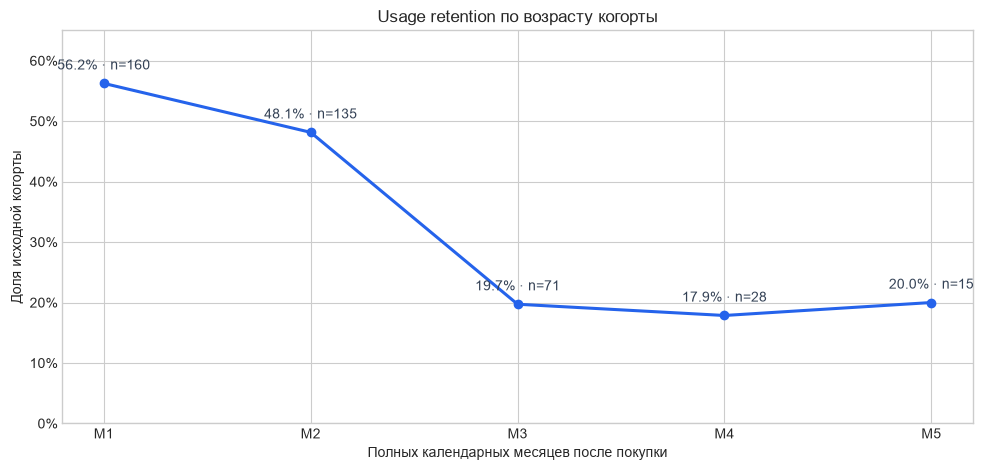

In [4]:
age_curve = overall[overall["month_number"].gt(0)]
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(
    age_curve["month_number"], age_curve["retention_rate"],
    color=COLORS["primary"], marker="o", linewidth=2.2,
)
for row in age_curve.itertuples():
    ax.annotate(
        f"{row.retention_rate:.1%} · n={row.eligible_subscriptions}",
        (row.month_number, row.retention_rate), xytext=(0, 10),
        textcoords="offset points", ha="center", color=COLORS["text"],
    )
ax.set(
    title="Usage retention по возрасту когорты",
    xlabel="Полных календарных месяцев после покупки",
    ylabel="Доля исходной когорты",
    xticks=age_curve["month_number"],
    ylim=(0, 0.65),
)
ax.set_xticklabels([f"M{value}" for value in age_curve["month_number"]])
ax.yaxis.set_major_formatter(PercentFormatter(1))
plt.tight_layout();

M3-бенчмарк равен **19,7%**, но его знаменатель меньше, чем у M1: поздние когорты ещё не успели созреть. Поэтому график показывает проблемный период жизненного цикла, а не точный последовательный отток одной и той же группы.

### 3. Cohort heatmap

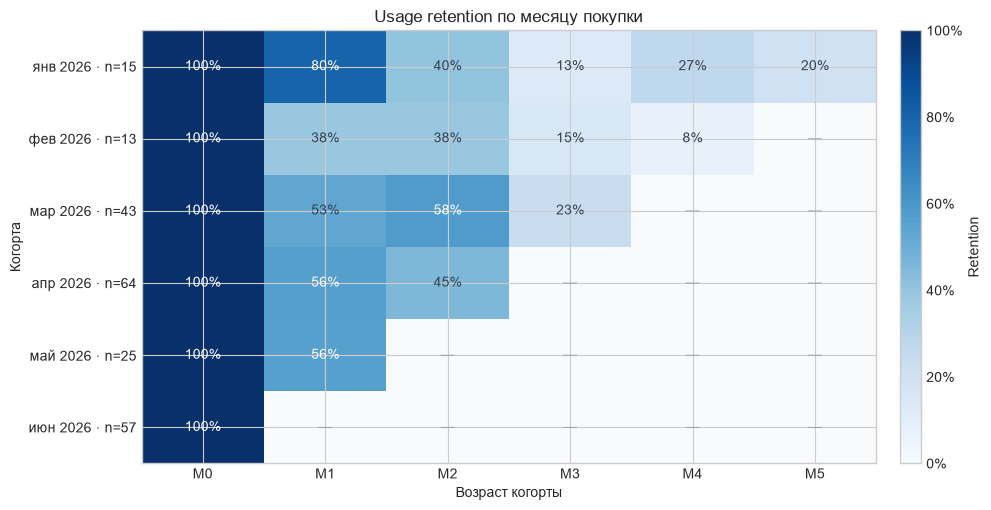

In [5]:
cohorts = (
    retention.groupby(["cohort_month", "month_number"], as_index=False)
    .agg(
        eligible_subscriptions=("subscription_id", "size"),
        retained_subscriptions=("retained", "sum"),
        retention_rate=("retained", "mean"),
    )
)
cohort_matrix = (
    cohorts.pivot(index="cohort_month", columns="month_number", values="retention_rate")
    .sort_index()
)
cohort_sizes = retention.loc[retention["month_number"].eq(0)].groupby("cohort_month").size()

cmap = plt.colormaps["Blues"].copy()
cmap.set_bad("#F8FAFC")
fig, ax = plt.subplots(figsize=(10, 5.2))
image = ax.imshow(cohort_matrix.to_numpy(), aspect="auto", cmap=cmap, vmin=0, vmax=1)
ax.set_xticks(range(len(cohort_matrix.columns)), [f"M{value}" for value in cohort_matrix.columns])
ax.set_yticks(
    range(len(cohort_matrix.index)),
    [
        f"{MONTHS_RU[value.month]} {value.year} · n={cohort_sizes.loc[value]}"
        for value in cohort_matrix.index
    ],
)
ax.set(title="Usage retention по месяцу покупки", xlabel="Возраст когорты", ylabel="Когорта")
for row_index in range(cohort_matrix.shape[0]):
    for column_index in range(cohort_matrix.shape[1]):
        value = cohort_matrix.iloc[row_index, column_index]
        label = "—" if pd.isna(value) else f"{value:.0%}"
        color = "#94A3B8" if pd.isna(value) else ("white" if value >= 0.55 else COLORS["text"])
        ax.text(column_index, row_index, label, ha="center", va="center", color=color)
colorbar = fig.colorbar(image, ax=ax, fraction=0.035, pad=0.03)
colorbar.ax.yaxis.set_major_formatter(PercentFormatter(1))
colorbar.set_label("Retention")
plt.tight_layout();

Крупные мартовская и апрельская когорты показывают M1 около 54–56%; ранние январь и февраль сильнее колеблются из-за размеров 15 и 13 подписок. Пустые клетки — незрелые периоды, а не нулевой retention.

### 4. M1 retention by segment

In [6]:
m1 = retention[retention["month_number"].eq(1)].copy()

def segment_summary(column, dimension, labels):
    result = (
        m1.groupby(column, as_index=False)
        .agg(
            eligible_subscriptions=("subscription_id", "size"),
            retained_subscriptions=("retained", "sum"),
            retention_rate=("retained", "mean"),
        )
    )
    return result.assign(
        dimension=dimension,
        segment=result[column].map(labels),
    )[["dimension", "segment", "eligible_subscriptions", "retained_subscriptions", "retention_rate"]]

segments = pd.concat(
    [
        segment_summary(
            "activated_7d", "7-day activation",
            {False: "Не активировались", True: "Активировались"},
        ),
        segment_summary("plan", "Тариф", {"basic": "Basic", "pro": "Pro"}),
        segment_summary(
            "sales_channel", "Канал продажи",
            {"website": "Сайт", "telegram_bot": "Telegram-бот"},
        ),
    ],
    ignore_index=True,
)
segment_display = segments.assign(
    retention=segments["retention_rate"].map(lambda value: f"{value:.1%}")
).drop(columns="retention_rate")
segment_display

,dimension,segment,eligible_subscriptions,retained_subscriptions,retention
0,7-day activation,Не активировались,57,21,36.8%
1,7-day activation,Активировались,103,69,67.0%
2,Тариф,Basic,127,67,52.8%
3,Тариф,Pro,33,23,69.7%
4,Канал продажи,Telegram-бот,116,68,58.6%
5,Канал продажи,Сайт,44,22,50.0%


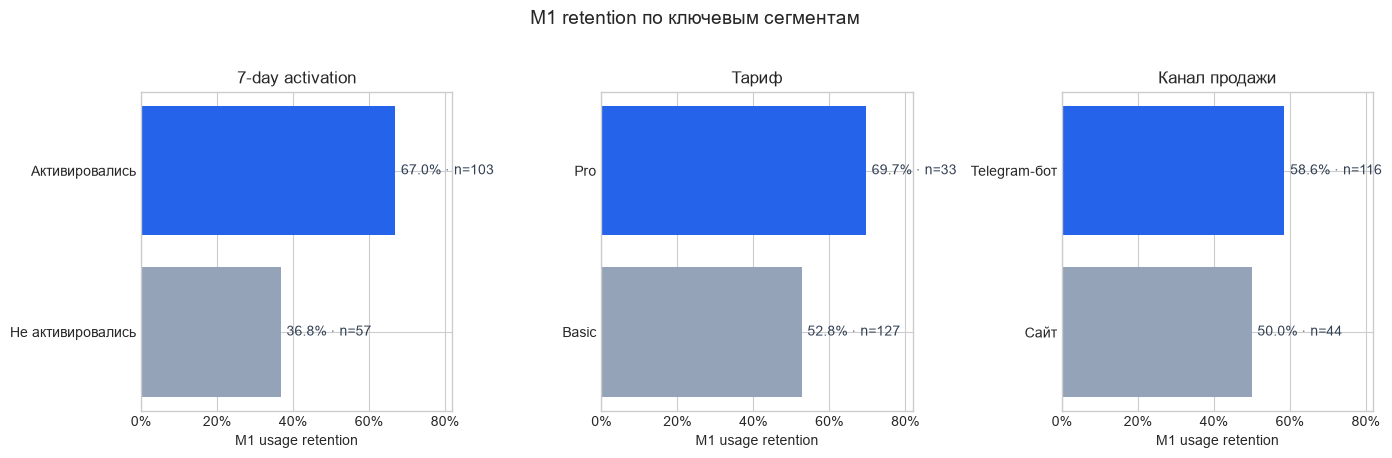

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), sharex=True)
for ax, dimension in zip(axes, ["7-day activation", "Тариф", "Канал продажи"]):
    rows = segments[segments["dimension"].eq(dimension)].sort_values("retention_rate")
    colors = [COLORS["secondary"], COLORS["primary"]]
    bars = ax.barh(rows["segment"], rows["retention_rate"], color=colors)
    for bar, row in zip(bars, rows.itertuples()):
        ax.text(
            row.retention_rate + 0.015,
            bar.get_y() + bar.get_height() / 2,
            f"{row.retention_rate:.1%} · n={row.eligible_subscriptions}",
            va="center", color=COLORS["text"],
        )
    ax.set_title(dimension)
    ax.set_xlim(0, 0.82)
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.set_xlabel("M1 usage retention")
fig.suptitle("M1 retention по ключевым сегментам", y=1.03, fontsize=14)
plt.tight_layout();

## Takeaways

1. **Главный lifecycle-риск — переход к M3.** В агрегате retention снижается с **48,1% в M2** до **19,7% в M3**. Рекомендуется запустить отдельный тест коммуникаций и сценариев возврата примерно на 30–75-й день, до попадания пользователя в этот период.
2. **Ранняя активация — сильный маркер будущего использования:** M1 равен **67,0%** у активировавшихся и **36,8%** у остальных. Приоритетная аудитория для HAPP-инструкций и поддержки — купившие подписку, но не активировавшиеся за 7 дней.
3. **Pro и Telegram выглядят устойчивее**, но выбор тарифа и канала не случаен. Разрывы нельзя использовать как доказательство того, что повышение цены или перевод пользователей в бот увеличит retention.
4. **Следующее измерение:** добавить причины отмены и неуспешного продления, затем оценить тесты отдельно по тарифу и каналу. До созревания новых когорт не сравнивать их M2–M3 с нулём.